# 5 · Evaluation — the three approaches on the frozen test split

**CRISP-DM phase 5.** Previous: [`4_Modeling/`](4_Modeling/) · Next: [`6_XAI.ipynb`](6_XAI.ipynb)

This is the **only notebook that loads the test split**. Every model saved in `models/` (the shared format of README rule 2) is evaluated once, with the settings frozen on validation in its modeling notebook, through the same `inference.Predictor` and the same `evaluation` report. Nothing is tuned here: if a result is disappointing, it is reported, not fixed.

**Earlier looks at the test split (disclosure).** The test images were evaluated before this notebook existed:

| Model | Earlier test evaluations | Where |
|---|---|---|
| A — DeepLabV3+ | 1 (Ines's original run); the test images had also been scored by an earlier CamVid model | `archive/A_deeplabv3plus_original_run_ines.ipynb` |
| B — pixel AE | 2 (ReLU code, then linear code) + Khaled's historical evaluation | `archive/B_feature_ae_and_backbone_study_adrian.ipynb`, `archive/B_pixel_ae_final_evaluation_khaled.ipynb` |
| B — feature AE | 1 | `archive/B_feature_ae_and_backbone_study_adrian.ipynb` |
| C — U-Nets (Walid) | 2, on Walid's own split (U-Net from scratch, U-Net ResNet34), before the port to the shared split | `archive/C_unet_original_run_walid.ipynb` |
| C — CNN (Hejer) | 0 | `archive/C_cnn_original_run_hejer.ipynb` |

No setting of the models below was changed because of those results (each change is documented with its validation evidence in the modeling notebooks), but the test set is not a perfectly untouched holdout and is reported as such.

**Business success criteria**, fixed in [`1_Business_Understanding.md`](1_Business_Understanding.md) before this run, are checked in section 6.

## TL;DR — the exam, taken once

**The exam.** Nine sealed photographs with 22 obstacles, all six models, every setting frozen on validation beforehand. Nothing is tuned after looking.

| Model | Test F1 [95 % interval] | Obstacles found | False alarms / blobs | Business tests passed |
|---|---|---|---|---|
| DeepLabV3+ (A) | **0.739** [0.62, 0.84] | **20/22** | 38/67 | 3 of 4 |
| U-Net ResNet50 (C) | 0.708 [0.59, 0.81] | 16/22 | 64/93 | 3 of 4 |
| Feature autoencoder (B) | 0.623 [0.51, 0.73] | 16/22 | **10/22** | **4 of 4** |
| U-Net from scratch (C) | 0.447 [0.35, 0.54] | 10/22 | 80/117 | 2 of 4 |
| CNN baseline (C) | 0.340 [0.23, 0.44] | 9/22 | 155/219 | 2 of 4 |
| Pixel autoencoder (B) | 0.248 [0.12, 0.39] | 16/22 | 40/45 | 2 of 4 |

**How to read the intervals.** With 9 photographs, luck matters: one easy photo more and a model looks better. The bootstrap redraws the 9 photographs 2,000 times (with repeats) and watches how much the score moves. The **paired** version compares two models on the same redraw, so a hard photo hurts both and cancels out. A difference counts only if its interval stays on one side of zero.

1. **A three-way tie at the top.** DeepLabV3+ leads the pretrained U-Net by +0.030 F1 [−0.010, 0.081] and the feature autoencoder by +0.115 [−0.030, 0.256]: both intervals cross zero, so no winner is declared. Each of the three is clearly better than each of the bottom three.
2. **Pretrained ImageNet features are the dividing line.** The three models that look at the image through an ImageNet network (as their encoder or as their input) score F1 ≥ 0.62; the three whose network learned to see from our 42 photographs alone score ≤ 0.45 (the pixel autoencoder uses VGG19 only inside its training loss).
3. **They fail differently.** The supervised models find the most obstacles (20/22 for DeepLabV3+) but sprinkle small false-alarm blobs, so fewer than half of their warnings are right (SC2 fails). The feature autoencoder drops blobs under 256 px, so 12 of its 22 warnings are right: it is the **only model that passes all four business tests**.
4. **Speed is not a problem:** 13–48 ms per photograph on a laptop RTX 4060 (the test needs < 100 ms).

**Recommendation.** DeepLabV3+ by default (the most accurate and among the fastest, 21 ms); the feature autoencoder where a false alarm is expensive.

## 0. Setup

In [1]:
# Import libraries
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")   # hide TensorFlow C++ log lines (e.g. the harmless "use_unbounded_threadpool" notice)
import json
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import keras
import tensorflow as tf
tf.get_logger().setLevel("ERROR")                    # hide tf.function retracing notices

from roadanomaly import data_pipeline as dp, evaluation, postprocessing as pp
from roadanomaly.gpu import setup_gpu
from roadanomaly.inference import Predictor, available_models
from roadanomaly.protocol import FPR_LIMIT, IMG_SIZE, SEED

import warnings
warnings.filterwarnings('ignore')

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
GPU_NAME = setup_gpu()
FIG_DIR = dp.FIG_DIR
RESULTS_DIR = dp.REPO_ROOT / "reports" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)


## 1. The models and a check before the test
Each model must give back, from its saved files, the validation AuPRC its modeling notebook recorded (to within 0.001: float32 GPU kernels reorder the many tied pixels of saturated sigmoids by about 0.0001, while a wrong model or post-processing moves it far more). This proves the saved model, its preprocessing and its post-processing are exactly those that were selected, before any test image is loaded.

In [2]:
MODEL_NAMES = available_models(dp.MODELS_DIR)
predictors = {name: Predictor(dp.MODELS_DIR / name) for name in MODEL_NAMES}
missing = [b for b in "ABC" if not any(p.config["binome"] == b for p in predictors.values())]
print("Models found:", MODEL_NAMES)
if missing:
    print("Not delivered yet (no folder in models/):", ["Binôme " + b for b in missing])

_, x_val, y_val = dp.load_split("val", IMG_SIZE)
gt_val = y_val[..., 0].astype(bool)
# Tolerance: models whose sigmoid saturates at exactly 1.0 have many tied pixels, and float32 GPU kernels
# (batch size, deterministic cuDNN algorithms) reorder those ties, moving AuPRC by ~1e-4. A wrong model,
# preprocessing or post-processing moves it by far more than 1e-3.
TOLERANCE = 1e-3
check = {}
for name, predictor in predictors.items():
    recorded = predictor.config["validation"]["AuPRC"]
    reproduced = pp.auprc(gt_val, predictor.score_maps(x_val))
    check[name] = {"recorded val AuPRC": recorded, "reproduced": reproduced, "difference": abs(recorded - reproduced)}
    assert abs(recorded - reproduced) < TOLERANCE, f"{name}: the saved model does not reproduce its validation score"
pd.DataFrame(check).T.round(6)

I0000 00:00:1793565177.204433 3216001 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6249 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Models found: ['A_deeplabv3plus', 'B_feature_ae', 'B_pixel_ae', 'C_cnn', 'C_unet', 'C_unet_resnet50']


,recorded val AuPRC,reproduced,difference
A_deeplabv3plus,0.753624,0.753624,0.000000
B_feature_ae,0.596010,0.596010,0.000000
B_pixel_ae,0.157301,0.157301,0.000000
C_cnn,0.410530,0.410531,0.000000
C_unet,0.452569,0.452675,0.000106
C_unet_resnet50,0.727943,0.727690,0.000253


## 2. Test evaluation (once)

In [3]:
test_frames, x_test, y_test = dp.load_split("test", IMG_SIZE)
gt_test = y_test[..., 0].astype(bool)
print(f"test: {len(test_frames)} images | anomaly prevalence {gt_test.mean():.4f} (AuPRC chance level)")

results = {}
for name, predictor in predictors.items():
    out = predictor.predict(x_test)
    results[name] = {"scores": out["scores"], "masks": out["masks"],
                     "free": evaluation.threshold_free_scores(gt_test, out["scores"]),
                     "report": evaluation.mask_report(gt_test, out["masks"])}
    val_out = predictor.predict(x_val)
    results[name]["val_free"] = evaluation.threshold_free_scores(gt_val, val_out["scores"])
    results[name]["val_report"] = evaluation.mask_report(gt_val, val_out["masks"])

title = {name: f"{p.config['binome']}: {p.config['title']}" for name, p in predictors.items()}
test_table = pd.DataFrame({title[n]: evaluation.summary(r["free"], r["report"]) for n, r in results.items()})
test_table.loc["AuPRC chance (prevalence)"] = gt_test.mean()
test_table

test: 9 images | anomaly prevalence 0.0859 (AuPRC chance level)


,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),B: Feature-space autoencoder on frozen VGG16 block5_conv3,"B: Pixel autoencoder (mae_vgg19 loss), baseline","C: CNN baseline (encoder-decoder, no skips)",C: U-Net from scratch,C: U-Net with ImageNet ResNet50 encoder
AuPRC (main),0.754601,0.631239,0.177529,0.352574,0.378494,0.686802
AUROC,0.964664,0.921758,0.676064,0.818376,0.868656,0.924826
AUPRO@0.3,0.899617,0.822724,0.503121,0.491579,0.684444,0.843764
FPR95 (lower is better),0.143854,0.44238,0.978125,0.563028,0.440452,0.533457
F1 = Dice (per-image mean),0.738747,0.623388,0.247633,0.339939,0.44725,0.708449
IoU (per-image mean),0.612923,0.47386,0.159458,0.216277,0.297905,0.569842
precision (per-image mean),0.717555,0.590333,0.180957,0.40341,0.559998,0.731378
recall (per-image mean),0.845606,0.769278,0.503058,0.417628,0.477456,0.777535
F1 (aggregated),0.74568,0.617737,0.244356,0.366147,0.447202,0.708771
Boundary IoU (15 px band),0.475897,0.235924,0.073142,0.182008,0.239167,0.446015


**How to read it.** AuPRC is the main ranking metric for score maps (chance = prevalence); AUROC looks good too easily on imbalanced pixels (chance 0.5); AUPRO weighs every obstacle the same up to FPR 0.3. F1 = Dice and IoU are per-image means of the thresholded masks. Boundary IoU (15-px band) and HD95 (px, lower is better) judge the outlines. The validation column below shows whether the settings chosen on validation transfer to unseen scenes.

In [4]:
# Validation vs test: do the choices made on validation transfer?
rows = {}
for name, r in results.items():
    rows[title[name]] = {"val AuPRC": r["val_free"]["AuPRC"], "test AuPRC": r["free"]["AuPRC"],
                         "val F1": r["val_report"]["pixel"]["per_image_mean"]["f1"],
                         "test F1": r["report"]["pixel"]["per_image_mean"]["f1"]}
pd.DataFrame(rows).T.round(3)

,val AuPRC,test AuPRC,val F1,test F1
A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),0.754,0.755,0.695,0.739
B: Feature-space autoencoder on frozen VGG16 block5_conv3,0.596,0.631,0.575,0.623
"B: Pixel autoencoder (mae_vgg19 loss), baseline",0.157,0.178,0.249,0.248
"C: CNN baseline (encoder-decoder, no skips)",0.411,0.353,0.503,0.340
C: U-Net from scratch,0.453,0.378,0.462,0.447
C: U-Net with ImageNet ResNet50 encoder,0.728,0.687,0.642,0.708


## 3. Uncertainty: bootstrap intervals and paired comparisons
With 9 test images, a single mean hides a large uncertainty. Each model gets 95 % bootstrap intervals over images; each **pair** of models gets a paired bootstrap interval of the per-image difference (same images, so image difficulty cancels out). A difference is established only when its interval excludes 0.

In [5]:
ci_rows = []
for name, r in results.items():
    table = evaluation.bootstrap_table(r["report"])
    table.insert(0, "model", title[name])
    ci_rows.append(table)
pd.concat(ci_rows).round(3).reset_index(drop=True)

,model,metric,mean,low,high
0,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),pixel f1,0.739,0.622,0.842
1,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),pixel iou,0.613,0.480,0.735
2,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),pixel precision,0.718,0.596,0.824
3,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),pixel recall,0.846,0.684,0.952
4,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),object f1,0.597,0.432,0.755
5,B: Feature-space autoencoder on frozen VGG16 b...,pixel f1,0.623,0.506,0.729
6,B: Feature-space autoencoder on frozen VGG16 b...,pixel iou,0.474,0.355,0.583
7,B: Feature-space autoencoder on frozen VGG16 b...,pixel precision,0.590,0.463,0.698
8,B: Feature-space autoencoder on frozen VGG16 b...,pixel recall,0.769,0.617,0.903
9,B: Feature-space autoencoder on frozen VGG16 b...,object f1,0.669,0.424,0.878


In [6]:
pair_rows = []
for a, b in combinations(results, 2):
    for key in ["f1", "iou"]:
        va = [s[key] for s in results[a]["report"]["pixel"]["per_image"]]
        vb = [s[key] for s in results[b]["report"]["pixel"]["per_image"]]
        mean, low, high = evaluation.paired_difference(va, vb)
        pair_rows.append({"A - B": f"{a} - {b}", "metric": f"per-image {key}", "mean difference": mean,
                          "95% low": low, "95% high": high, "established": "yes" if low > 0 or high < 0 else "no"})
pd.DataFrame(pair_rows).round(3)

,A - B,metric,mean difference,95% low,95% high,established
0,A_deeplabv3plus - B_feature_ae,per-image f1,0.115,-0.030,0.256,no
1,A_deeplabv3plus - B_feature_ae,per-image iou,0.139,-0.015,0.292,no
2,A_deeplabv3plus - B_pixel_ae,per-image f1,0.491,0.267,0.699,yes
3,A_deeplabv3plus - B_pixel_ae,per-image iou,0.453,0.251,0.638,yes
4,A_deeplabv3plus - C_cnn,per-image f1,0.399,0.229,0.539,yes
5,A_deeplabv3plus - C_cnn,per-image iou,0.397,0.236,0.533,yes
6,A_deeplabv3plus - C_unet,per-image f1,0.291,0.180,0.403,yes
7,A_deeplabv3plus - C_unet,per-image iou,0.315,0.194,0.434,yes
8,A_deeplabv3plus - C_unet_resnet50,per-image f1,0.030,-0.010,0.081,no
9,A_deeplabv3plus - C_unet_resnet50,per-image iou,0.043,-0.015,0.117,no


## 4. Per image: where each approach works and fails

In [7]:
per_image = pd.DataFrame({"frame": [f[:32] for f in test_frames],
                          "anomaly %": (100 * gt_test.mean(axis=(1, 2))).round(1),
                          "objects": results[MODEL_NAMES[0]]["report"]["objects"]["gt_objects"].values})
for name, r in results.items():
    per_image[f"{name} F1"] = [round(s["f1"], 3) for s in r["report"]["pixel"]["per_image"]]
    per_image[f"{name} found"] = r["report"]["objects"]["detected"].values
    per_image[f"{name} false alarms"] = r["report"]["objects"]["false_alarms"].values
per_image

,frame,anomaly %,objects,A_deeplabv3plus F1,A_deeplabv3plus found,A_deeplabv3plus false alarms,B_feature_ae F1,B_feature_ae found,B_feature_ae false alarms,B_pixel_ae F1,...,B_pixel_ae false alarms,C_cnn F1,C_cnn found,C_cnn false alarms,C_unet F1,C_unet found,C_unet false alarms,C_unet_resnet50 F1,C_unet_resnet50 found,C_unet_resnet50 false alarms
0,animals14_Dekemhare_Road,10.0,2,0.839,2,4,0.763,2,0,0.098,...,3,0.525,2,21,0.624,2,11,0.750,2,3
1,animals17_E6_near_Kvaenangen,1.6,1,0.728,1,3,0.447,1,3,0.138,...,1,0.279,0,11,0.509,1,5,0.726,1,9
2,animals20_Marcassin_Conchiglio,4.3,1,0.814,1,15,0.772,1,0,0.013,...,3,0.278,1,18,0.550,0,1,0.818,1,17
3,animals21_On_The_Road_to_Gondar_,15.2,2,0.632,2,4,0.659,1,0,0.468,...,11,0.469,2,31,0.441,2,11,0.675,2,16
4,animals29_Zebra_Crossing_Abbey_R,7.0,2,0.858,2,3,0.697,2,0,0.599,...,1,0.123,0,6,0.422,1,11,0.801,2,1
5,cones06_VnA_traffic_cones,5.0,6,0.563,6,5,0.339,4,4,0.263,...,4,0.029,1,38,0.150,1,24,0.579,3,10
6,obstacles09_boulder3,5.1,1,0.910,1,0,0.825,1,0,0.000,...,4,0.446,0,9,0.598,0,0,0.940,1,0
7,obstacles10_boulder4,19.1,3,0.925,2,2,0.399,1,1,0.135,...,5,0.393,0,5,0.322,0,5,0.735,1,6
8,vehicle02_Broadmoor_Cones_Skidlo,10.0,4,0.379,3,2,0.710,3,2,0.514,...,8,0.517,3,16,0.410,3,12,0.351,3,2


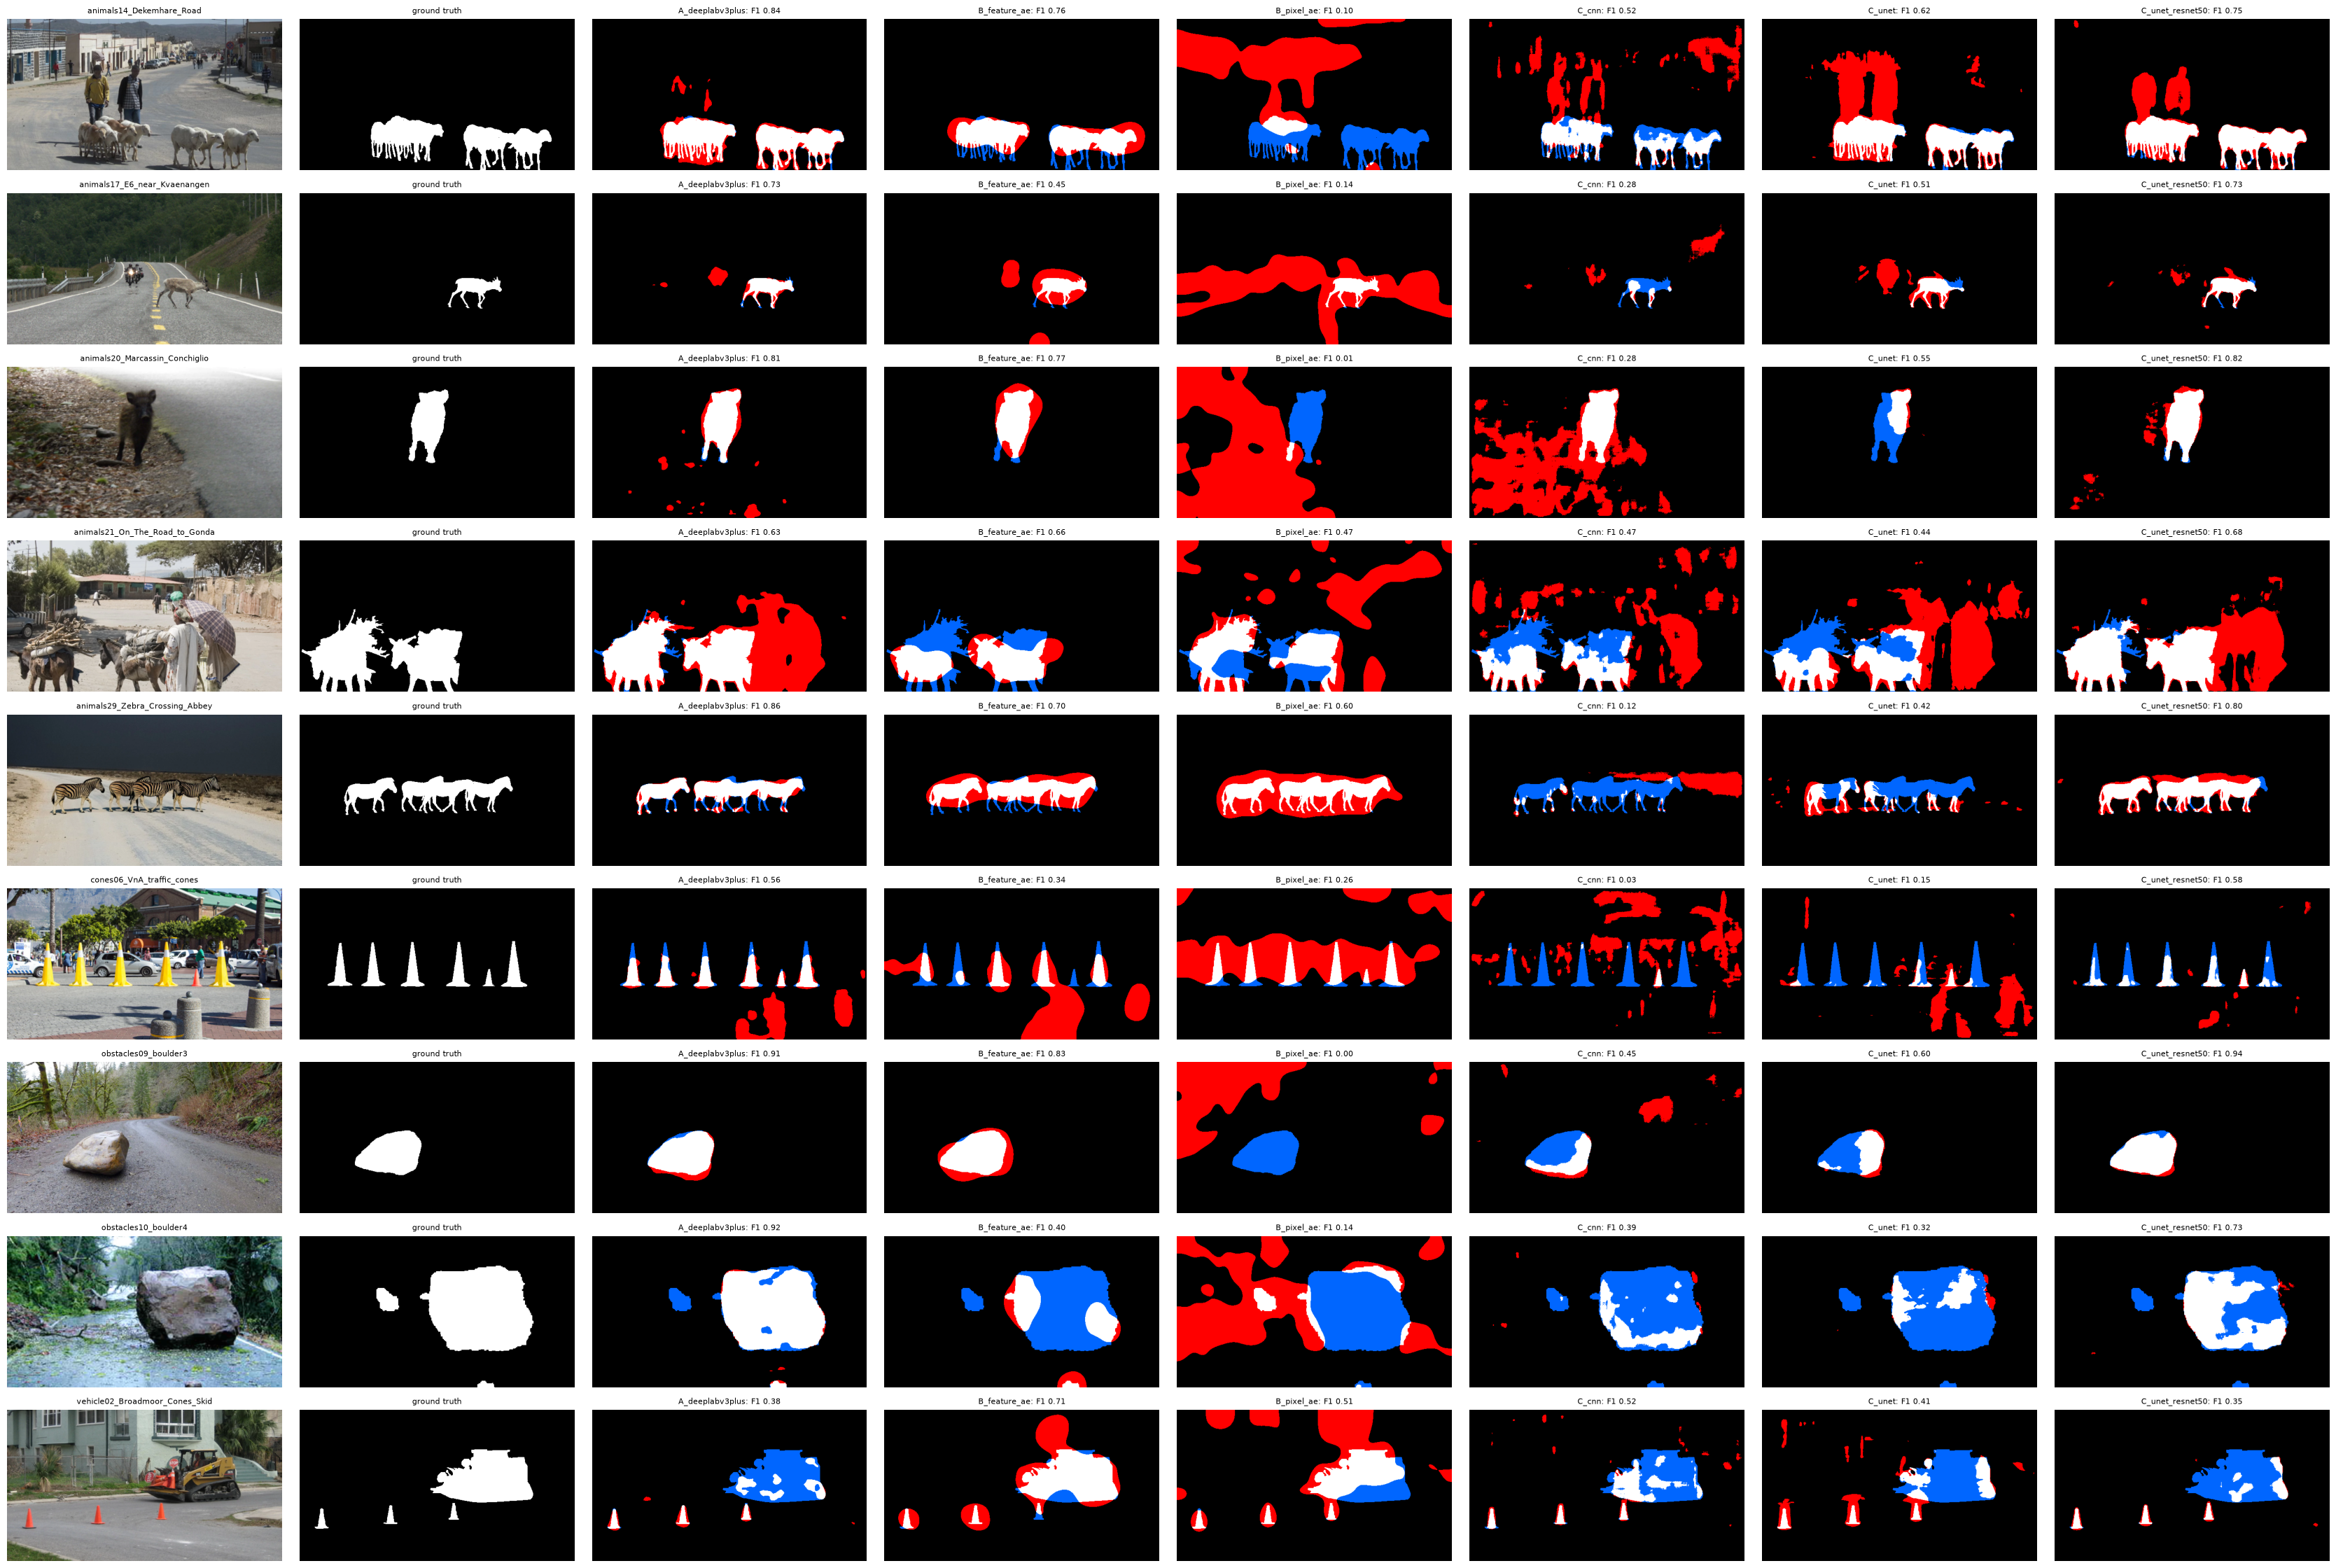

In [8]:
# Every test image: image | ground truth | prediction of each model (TP white, FP red, FN blue)
def error_overlay(truth, pred):
    errors = np.zeros((*truth.shape, 3), np.float32)
    errors[truth & pred] = (1, 1, 1); errors[~truth & pred] = (1, 0, 0); errors[truth & ~pred] = (0, 0.4, 1)
    return errors

n_cols = 2 + len(results)
fig, ax = plt.subplots(len(test_frames), n_cols, figsize=(4.2 * n_cols, 2.5 * len(test_frames)), tight_layout=True)
for i, frame in enumerate(test_frames):
    ax[i, 0].imshow(x_test[i]); ax[i, 0].set_title(frame[:30], fontsize=8)
    ax[i, 1].imshow(gt_test[i], cmap="gray"); ax[i, 1].set_title("ground truth", fontsize=8)
    for j, (name, r) in enumerate(results.items(), start=2):
        ax[i, j].imshow(error_overlay(gt_test[i], r["masks"][i].astype(bool)))
        ax[i, j].set_title(f"{name}: F1 {r['report']['pixel']['per_image'][i]['f1']:.2f}", fontsize=8)
for a in ax.flat:
    a.axis("off")
plt.savefig(FIG_DIR / "5_01_test_predictions.png", dpi=55)
plt.show()

## 5. Cost, complexity and data needs
FR asks to compare the approaches also on computation, complexity and the training data they need. Latency is the full `Predictor.predict` (score map + mask, post-processing included) on this notebook's GPU, batch of 9 images; it is a measurement, not a real-time promise.

In [9]:
cost = {}
for name, predictor in predictors.items():
    model = predictor.model
    trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    total = model.count_params()
    if predictor.model_type == "feature_autoencoder":   # the frozen backbone runs too
        from roadanomaly.models.feature_ae import get_extractor
        total += get_extractor(predictor.backbone, predictor.layer).count_params()
    cost[title[name]] = {
        "parameters, total (M)": total / 1e6, "trained parameters (M)": trainable / 1e6,
        "model file (MB)": (predictor.directory / predictor.config["model_file"]).stat().st_size / 1e6,
        f"latency (ms / image, {GPU_NAME})": evaluation.latency_ms(predictor.predict, x_test),
        "training labels needed": "pixel masks" if predictor.model_type == "segmentation"
                                  else "normal regions only (masks used to exclude obstacles)",
    }
cost_table = pd.DataFrame(cost).T
cost_table.round(2)

,"parameters, total (M)",trained parameters (M),model file (MB),"latency (ms / image, NVIDIA GeForce RTX 4060 Laptop GPU)",training labels needed
A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),12.838721,4.247649,51.997426,21.082778,pixel masks
B: Feature-space autoencoder on frozen VGG16 block5_conv3,16.04692,1.332232,16.020657,39.672716,normal regions only (masks used to exclude obs...
"B: Pixel autoencoder (mae_vgg19 loss), baseline",0.786053,0.786053,3.193364,26.486059,normal regions only (masks used to exclude obs...
"C: CNN baseline (encoder-decoder, no skips)",0.186225,0.185553,0.847846,12.872058,pixel masks
C: U-Net from scratch,1.946993,1.944049,8.03855,15.624219,pixel masks
C: U-Net with ImageNet ResNet50 encoder,30.550753,30.442529,122.998646,48.477373,pixel masks


## 6. Business success criteria
The criteria of [`1_Business_Understanding.md`](1_Business_Understanding.md) (section 4), checked on the test split:
- **SC1 — better than doing nothing smart:** the lower bound of the 95 % interval of the per-image F1 is above the "all anomaly" baseline on test.
- **SC2 — useful warnings:** more than half of the predicted blobs are real obstacles (object precision over all blobs > 0.5), so an alert is more often right than wrong.
- **SC3 — obstacles found:** at least half of the annotated obstacles are detected (object recall over all objects ≥ 0.5).
- **SC4 — demonstrable:** inference under 100 ms per image on a laptop GPU (≥ 10 images per second, enough for the demo and frame-by-frame video).

In [10]:
baseline_f1 = evaluation.trivial_baselines(gt_test)["all anomaly"]["f1"]
criteria = {}
for name, r in results.items():
    objects = r["report"]["objects"]
    low_f1 = evaluation.bootstrap_table(r["report"]).set_index("metric").loc["pixel f1", "low"]
    precision = 1 - objects["false_alarms"].sum() / max(objects["pred_objects"].sum(), 1)
    recall = objects["detected"].sum() / objects["gt_objects"].sum()
    latency = cost[title[name]][f"latency (ms / image, {GPU_NAME})"]
    criteria[title[name]] = {
        "SC1 F1 low bound > all-anomaly": f"{low_f1:.3f} > {baseline_f1:.3f}: {'pass' if low_f1 > baseline_f1 else 'FAIL'}",
        "SC2 object precision > 0.5": f"{precision:.2f}: {'pass' if precision > 0.5 else 'FAIL'}",
        "SC3 object recall >= 0.5": f"{recall:.2f}: {'pass' if recall >= 0.5 else 'FAIL'}",
        "SC4 latency < 100 ms": f"{latency:.0f} ms: {'pass' if latency < 100 else 'FAIL'}",
    }
pd.DataFrame(criteria)

,A: DeepLabV3+ (frozen ImageNet ResNet50 encoder),B: Feature-space autoencoder on frozen VGG16 block5_conv3,"B: Pixel autoencoder (mae_vgg19 loss), baseline","C: CNN baseline (encoder-decoder, no skips)",C: U-Net from scratch,C: U-Net with ImageNet ResNet50 encoder
SC1 F1 low bound > all-anomaly,0.622 > 0.154: pass,0.506 > 0.154: pass,0.118 > 0.154: FAIL,0.230 > 0.154: pass,0.351 > 0.154: pass,0.594 > 0.154: pass
SC2 object precision > 0.5,0.43: FAIL,0.55: pass,0.11: FAIL,0.29: FAIL,0.32: FAIL,0.31: FAIL
SC3 object recall >= 0.5,0.91: pass,0.73: pass,0.73: pass,0.41: FAIL,0.45: FAIL,0.73: pass
SC4 latency < 100 ms,21 ms: pass,40 ms: pass,26 ms: pass,13 ms: pass,16 ms: pass,48 ms: pass


## 7. Save the results
Every number of this notebook is written to `reports/results/` (tracked in git), so the report, the README and the demo quote the same values.

In [11]:
def jsonable(report):
    return {"pixel": report["pixel"], "objects": report["objects"].to_dict(orient="list"), "sizes": report["sizes"],
            "boundary": report["boundary"], "confusion": report["confusion"]}

saved = {"split": "test", "frames": test_frames, "environment": {"gpu": GPU_NAME, "tensorflow": tf.__version__},
         "models": {name: {"title": title[name], "binome": predictors[name].config["binome"],
                           "model_type": predictors[name].model_type, "config": predictors[name].config,
                           "threshold_free": r["free"], "summary": evaluation.summary(r["free"], r["report"]),
                           "bootstrap": evaluation.bootstrap_table(r["report"]).to_dict(orient="records"),
                           "criteria": criteria[title[name]], "cost": cost[title[name]],
                           "report": jsonable(r["report"]), "validation_threshold_free": r["val_free"]}
                    for name, r in results.items()},
         "paired_differences": pair_rows}
(RESULTS_DIR / "test_results.json").write_text(json.dumps(saved, indent=2, default=float), encoding="utf-8")
test_table.to_csv(RESULTS_DIR / "test_summary.csv")
pd.DataFrame(pair_rows).to_csv(RESULTS_DIR / "test_paired_differences.csv", index=False)
cost_table.to_csv(RESULTS_DIR / "cost.csv")
print("saved:", sorted(p.name for p in RESULTS_DIR.iterdir()))

saved: ['cost.csv', 'test_paired_differences.csv', 'test_results.json', 'test_summary.csv']


## 8. Conclusions
**Ranking (per-image mean F1 on the 9 test photographs, 95 % bootstrap interval).**

| Model | Test AuPRC | Test F1 [95 % CI] | Obstacles found | False alarms / blobs | Business criteria met |
|---|---|---|---|---|---|
| A — DeepLabV3+ | **0.755** | **0.739** [0.62, 0.84] | 20/22 | 38/67 | 3 of 4 (fails SC2) |
| C — U-Net ResNet50 | 0.687 | 0.708 [0.59, 0.81] | 16/22 | 64/93 | 3 of 4 (fails SC2) |
| B — feature autoencoder | 0.631 | 0.623 [0.51, 0.73] | 16/22 | 10/22 | **4 of 4** |
| C — U-Net from scratch | 0.378 | 0.447 [0.35, 0.54] | 10/22 | 80/117 | 2 of 4 |
| C — CNN baseline | 0.353 | 0.340 [0.23, 0.44] | 9/22 | 155/219 | 2 of 4 |
| B — pixel autoencoder | 0.178 | 0.248 [0.12, 0.39] | 16/22 | 40/45 | 2 of 4 |

1. **No winner among the top three.** The paired bootstrap differences are not established: A − U-Net ResNet50 = +0.030 [−0.010, 0.081], A − feature AE = +0.115 [−0.030, 0.256], feature AE − U-Net ResNet50 = −0.085 [−0.199, 0.051]. Each of the three is established as better than the CNN baseline, the U-Net from scratch and the pixel autoencoder.
2. **Pretrained features decide.** The three models above 0.6 all build on frozen or fine-tuned ImageNet encoders; the models trained from scratch on 42 photographs stay below 0.45. For the autoencoders this is the finding of notebook 4/B: a Gaussian on the same features does about as well.
3. **Validation transferred for the strong models, not for the CNN.** A (0.695 → 0.739), the feature AE (0.575 → 0.623) and the U-Net ResNet50 (0.642 → 0.708) held up; the CNN baseline fell from 0.503 to 0.340, a sign that choosing its best epoch among 80 on nine validation photographs over-fitted the validation set.
4. **How they fail differs.** The supervised models find the most obstacles and draw the best outlines (Boundary IoU 0.48 for A) but scatter small false-alarm blobs, which is why they fail SC2 (object precision 0.43 and 0.31). The feature AE removes blobs under 256 px (chosen on validation), so most of its warnings are real, at the cost of coarse 16-px outlines and small obstacles. The pixel AE reacts to texture, not to objects.
5. **Cost is not a constraint.** Every model runs in 13–48 ms per photograph on the RTX 4060. The U-Net ResNet50 is the heaviest (30.4 M trained parameters, 123 MB); the feature AE needs no annotated obstacle to learn, only masks to exclude obstacles from its normal data.

**Recommendation.** For the demo, DeepLabV3+ by default (the most accurate and among the fastest); for a warning system where false alarms are costly, the feature autoencoder, the only model that meets all four business criteria. The next step that can be justified without touching the test set again: choose a minimum blob size on validation for the supervised models, as Binôme B did, to lower their false alarms.

**Caveats.** Nine test photographs and 22 obstacles, none of them small (small-object behaviour is judged on validation only); earlier looks at the test set are disclosed at the top of this notebook; RoadAnomaly is used here for training and testing, so these are not out-of-distribution benchmark scores.